<a href="https://colab.research.google.com/github/SattikBhaumik/CS156/blob/main/CS156_Session_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Max likelihood 2: Parameter Estimation from Data

In [1]:
import numpy as np
from sklearn import metrics
import matplotlib.pyplot as plt

NUM_DATAPOINTS = 1000

def sigmoid(x):
    return np.exp(x) / (1 + np.exp(x))

def generate_data(x):
    a = 3  #beta_1
    b = -5  #beta_0
    prob = sigmoid(a*x+b)
    return np.random.uniform() < prob

x_data = np.random.uniform(high=3, size=NUM_DATAPOINTS)
y_data = [generate_data(x) for x in x_data]

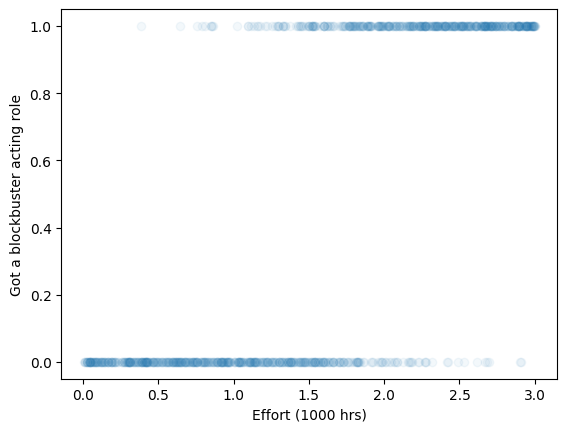

In [2]:
plt.scatter(x_data, y_data, alpha=0.05)
plt.xlabel("Effort (1000 hrs)")
plt.ylabel("Got a blockbuster acting role")
plt.show()

In [3]:
# Fix this function
# You might wish to use the sigmoid(x) function defined above!
def log_likelihood_per_point(beta_0, beta_1, x, y):
    prob = sigmoid(beta_1*x+beta_0)  # this should be only one line!
    if y is True:
        return np.log(prob)  # Think simple!
    else:
        return np.log(1 - prob)  # Again, think simple!


# This one's complete!
def total_log_likelihood(beta_0, beta_1, xs, ys):
    total_ll = 0

    for (x, y) in zip(xs, ys):
        total_ll += log_likelihood_per_point(beta_0, beta_1, x, y)

    return total_ll

# Be careful, which is the *higher* value when two values are negative?
print(total_log_likelihood(3, -3, x_data, y_data))
print(total_log_likelihood(4, -1, x_data, y_data))

'''
(Beta0, Beta1) = (3, -3) is the better choice.
(4, -1) is more wrong since it has lower log-likelihood value.
'''

-647.2153890277317
-2568.233544815568


'\n(Beta0, Beta1) = (3, -3) is the better choice.\n(4, -1) is more wrong since it has lower log-likelihood value.\n'

##Gradient

In [4]:
'''
%pip install jax[cpu]
import jax
import jax.numpy as jnp
'''
## JAX is not working due to some version conflict. Hence, I am using numpy

import numpy as np
x_array = np.array(x_data)
y_array = np.array(y_data)

def sigmoid(t):
    return np.exp(t) / (1 + np.exp(t))

def log_likelihood_function(beta_0, beta_1, x, y):
    prob_value = sigmoid(beta_1 * x + beta_0)
    return np.sum(y * prob_value), np.sum(x * (y - prob_value))

gradient_Aish = log_likelihood_function(3.0, -3.0, x_array, y_array)

print("Gradient value at Beta0: ", gradient_Aish[0])
print("Gradient value at Beta1: ", gradient_Aish[1])

Gradient value at Beta0:  29.06824580714394
Gradient value at Beta1:  815.6384367484599
